In [1]:
import pandas as pd

DATA_PATH = "../data/raw/"

#Loading of training data
afr_tr = pd.read_csv(DATA_PATH + "afr_train.csv")
deu_tr = pd.read_csv(DATA_PATH + "deu_train.csv")
ron_tr = pd.read_csv(DATA_PATH + "ron_train.csv")

#Loading of dev data
afr_dev = pd.read_csv(DATA_PATH + "afr_dev.csv")
deu_dev = pd.read_csv(DATA_PATH + "deu_dev.csv")
ron_dev = pd.read_csv(DATA_PATH + "ron_dev.csv")

#Loading of test data
afr_ts = pd.read_csv(DATA_PATH + "afr_test.csv")
deu_ts = pd.read_csv(DATA_PATH + "deu_test.csv")
ron_ts = pd.read_csv(DATA_PATH + "ron_test.csv")

In [2]:
#Printing of data
print("Training data:")
print(f"Afrikaans: {afr_tr.head(3)}")
print(f"German: {deu_tr.head(3)}")
print(f"Romanian: {ron_tr.head(3)}")

Training data:
Afrikaans:                         id                                               text  \
0  afr_train_track_a_00001  die grondeienaars het die departement genader ...   
1  afr_train_track_a_00002  dit is verder 'n erkende feit dat daar menings...   
2  afr_train_track_a_00003  baie families in die wes-kaap is in rou gedomp...   

   anger  disgust  fear  joy  sadness  surprise     emotions  
0      0        0     0    0        0       NaN           []  
1      0        0     0    0        0       NaN           []  
2      0        0     0    0        1       NaN  ['sadness']  
German:                         id                                               text  \
0  deu_train_track_a_00001  hallo an alle lesenden, da ich jetzt erstmal e...   
1  deu_train_track_a_00002  du warst bestimmt schon in verschiedenen lände...   
2  deu_train_track_a_00003  wenn ihr um geld spielt bei bingo, fangen sie ...   

   anger  disgust  fear  joy  sadness  surprise  emotions  
0   

In [3]:
#Multilabel count
def n_multilabel(file):
    n_emotions = file["emotions"].str.count("'") // 2
    n_multilabel = (n_emotions > 1).sum()
    return n_multilabel

#Count all rows
def row_count(file):
    return len(file)

#How much percentage of all rows are multilabels
def multilabel_pct(multilabel, total):
    return (multilabel / total) * 100

#Print format for all three previous methods
def format(file):
    multilabel = n_multilabel(file)
    total_rows = row_count(file)
    pct_multi = multilabel_pct(multilabel, total_rows)

    statement = f"Multilabel: {multilabel}\nTotal Rows: {total_rows}\nPercentage of Multilabels: {pct_multi:.2f}%\n"
    print(statement)

In [4]:
#Check validity of multilabel_count method
def test_multilabel_count(file):
    n_emotions = file["emotions"].str.count("'") // 2
    no_emotion = file[n_emotions == 0]["emotions"].head()
    one_emotion = file[n_emotions == 1]["emotions"].head()
    many_emotions = file[n_emotions > 1]["emotions"].head()
    print(f"No Emotion:\n{no_emotion}\nOne Emotion:\n{one_emotion}\nMultiple Emotions:\n{many_emotions}")

test_multilabel_count(deu_tr)

No Emotion:
1    []
2    []
4    []
8    []
9    []
Name: emotions, dtype: object
One Emotion:
0        ['fear']
6     ['sadness']
10        ['joy']
11      ['anger']
12    ['sadness']
Name: emotions, dtype: object
Multiple Emotions:
3       ['disgust' 'joy']
5     ['anger' 'disgust']
7     ['anger' 'disgust']
17    ['anger' 'disgust']
18    ['anger' 'disgust']
Name: emotions, dtype: object


In [5]:
#Multilabel Analysation for Afrikaans
print("Training Dataset")
tr_multilabel = format(afr_tr)

print("Dev Dataset")
dev_multilabel = format(afr_dev)

print("Test Dataset")
ts_multilabel = format(afr_ts)

Training Dataset
Multilabel: 96
Total Rows: 1222
Percentage of Multilabels: 7.86%

Dev Dataset
Multilabel: 26
Total Rows: 196
Percentage of Multilabels: 13.27%

Test Dataset
Multilabel: 284
Total Rows: 2130
Percentage of Multilabels: 13.33%



In [6]:
# Multilabel Analysation for German
print("Training Dataset")
tr_multilabel = format(deu_tr)

print("Dev Dataset")
dev_multilabel = format(deu_dev)

print("Test Dataset")
ts_multilabel = format(deu_ts)

Training Dataset
Multilabel: 879
Total Rows: 2603
Percentage of Multilabels: 33.77%

Dev Dataset
Multilabel: 138
Total Rows: 400
Percentage of Multilabels: 34.50%

Test Dataset
Multilabel: 1752
Total Rows: 5208
Percentage of Multilabels: 33.64%



In [7]:
# Multilabel Analysation for Romanian
print("Training Dataset")
tr_multilabel = format(ron_tr)

print("Dev Dataset")
dev_multilabel = format(ron_dev)

print("Test Dataset")
ts_multilabel = format(ron_ts)

Training Dataset
Multilabel: 670
Total Rows: 1241
Percentage of Multilabels: 53.99%

Dev Dataset
Multilabel: 124
Total Rows: 246
Percentage of Multilabels: 50.41%

Test Dataset
Multilabel: 1244
Total Rows: 2238
Percentage of Multilabels: 55.59%



In [8]:
#Multilabel count
def multilabel_combo(file):
    multilabel_count = {}
    for emotion in file["emotions"]:
        stripped_emotion = emotion.replace("'", "").split()
        tuple_emotion = tuple(sorted(stripped_emotion))
        if len(tuple_emotion) > 1:
            if tuple_emotion in multilabel_count:
                multilabel_count[tuple_emotion] += 1
            else:
                multilabel_count[tuple_emotion] = 1
    return multilabel_count



print(multilabel_combo(deu_tr))
print(multilabel_combo(deu_dev))
print(multilabel_combo(deu_ts))

{('[disgust', 'joy]'): 24, ('[anger', 'disgust]'): 358, ('[anger', 'disgust', 'fear]'): 26, ('[fear', 'sadness]'): 45, ('[anger', 'joy]'): 13, ('[anger', 'disgust', 'fear', 'sadness]'): 11, ('[anger', 'surprise]'): 17, ('[disgust', 'sadness]'): 56, ('[joy', 'sadness]'): 36, ('[anger', 'sadness]'): 33, ('[disgust', 'surprise]'): 15, ('[anger', 'disgust', 'sadness]'): 111, ('[anger', 'fear]'): 13, ('[anger', 'disgust', 'surprise]'): 18, ('[joy', 'surprise]'): 38, ('[fear', 'joy]'): 5, ('[anger', 'disgust', 'joy]'): 12, ('[disgust', 'fear', 'sadness]'): 11, ('[disgust', 'fear]'): 13, ('[sadness', 'surprise]'): 4, ('[fear', 'joy', 'sadness]'): 2, ('[anger', 'joy', 'surprise]'): 1, ('[anger', 'sadness', 'surprise]'): 3, ('[anger', 'fear', 'sadness]'): 3, ('[disgust', 'fear', 'surprise]'): 2, ('[disgust', 'sadness', 'surprise]'): 1, ('[anger', 'disgust', 'sadness', 'surprise]'): 1, ('[disgust', 'joy', 'sadness]'): 1, ('[fear', 'surprise]'): 4, ('[anger', 'joy', 'sadness]'): 1, ('[anger', 'di

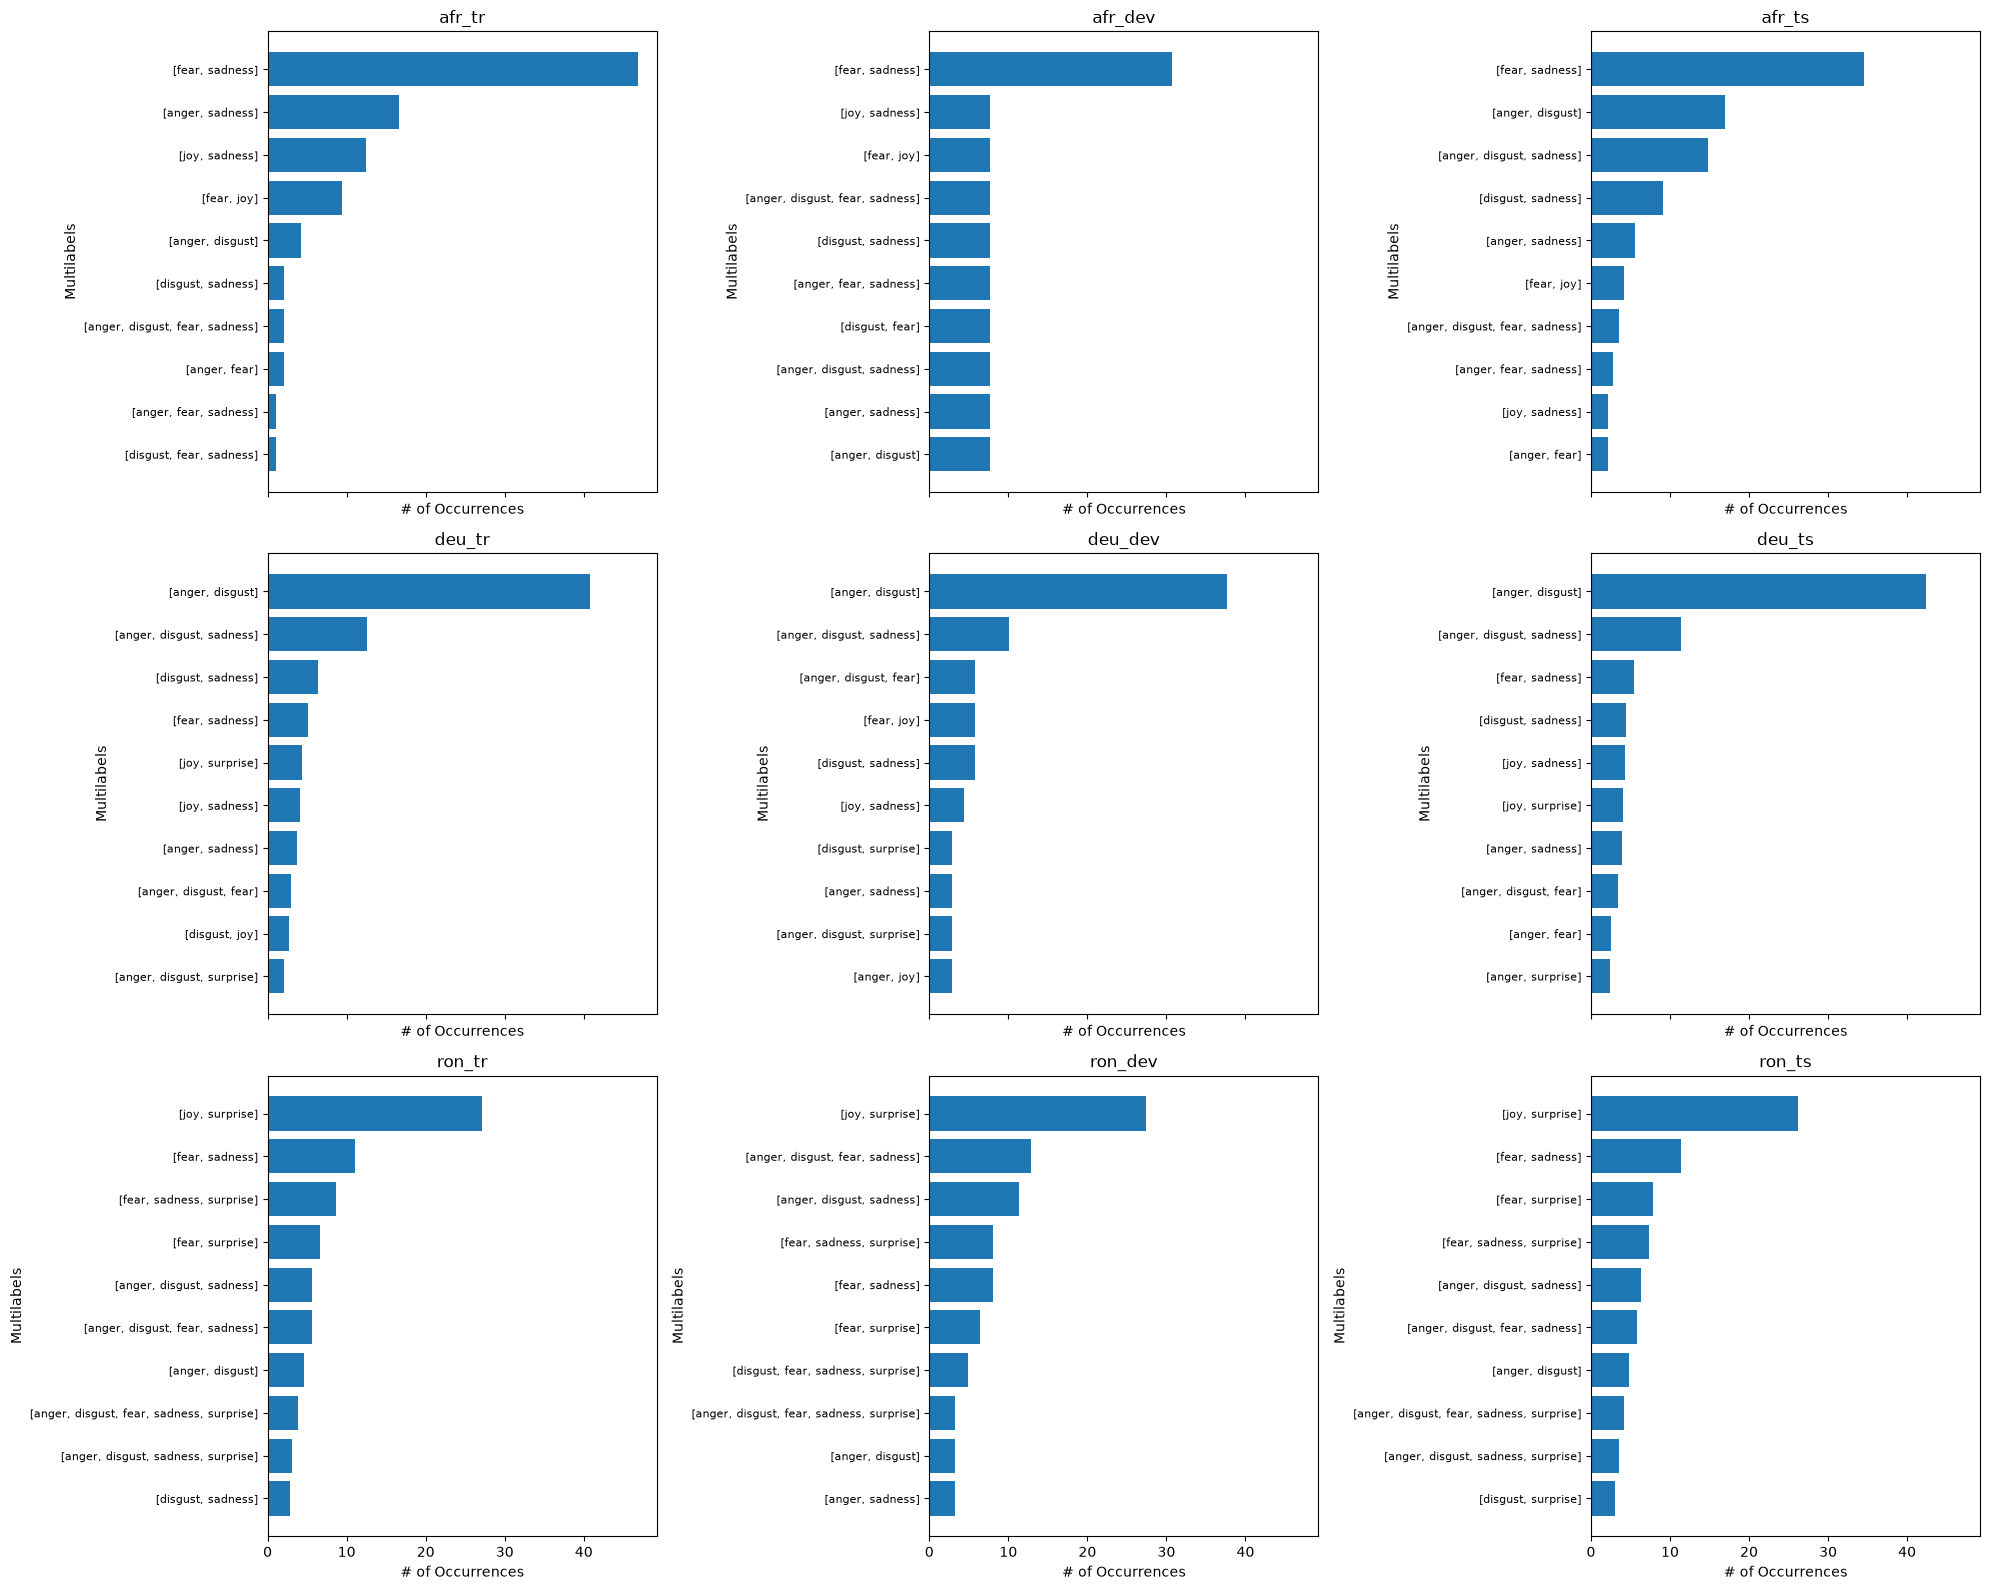

In [18]:
import matplotlib.pyplot as plt

def multilabel_plot(file, ax, title, top_n=10):
    multilabel_file = multilabel_combo(file)
    total = sum(multilabel_file.values())

    top = sorted(multilabel_file.items(), key=lambda item: item[1], reverse=True)[:top_n]
    x = [", ".join(k) for k, v in top]
    y = [v/ total * 100 for k, v in top]

    ax.barh(x, y)
    ax.invert_yaxis()
    ax.set_xlabel("# of Occurrences")
    ax.set_ylabel("Multilabels")
    ax.set_title(title)
    ax.tick_params(axis="y", labelsize=8)


datasets = {
    "afr_tr": afr_tr, "afr_dev": afr_dev, "afr_ts": afr_ts,
    "deu_tr": deu_tr, "deu_dev": deu_dev, "deu_ts": deu_ts,
    "ron_tr": ron_tr, "ron_dev": ron_dev, "ron_ts": ron_ts,
}

fig, axes = plt.subplots(3, 3, figsize=(20, 16), sharex=True)
for ax, (name, df) in zip(axes.flatten(), datasets.items()):
    multilabel_plot(df, ax, name)

plt.tight_layout()
plt.show()